# Rag From Scratch: Overview

These notebooks walk through the process of building RAG app(s) from scratch.

They will build towards a broader understanding of the RAG langscape, as shown here:

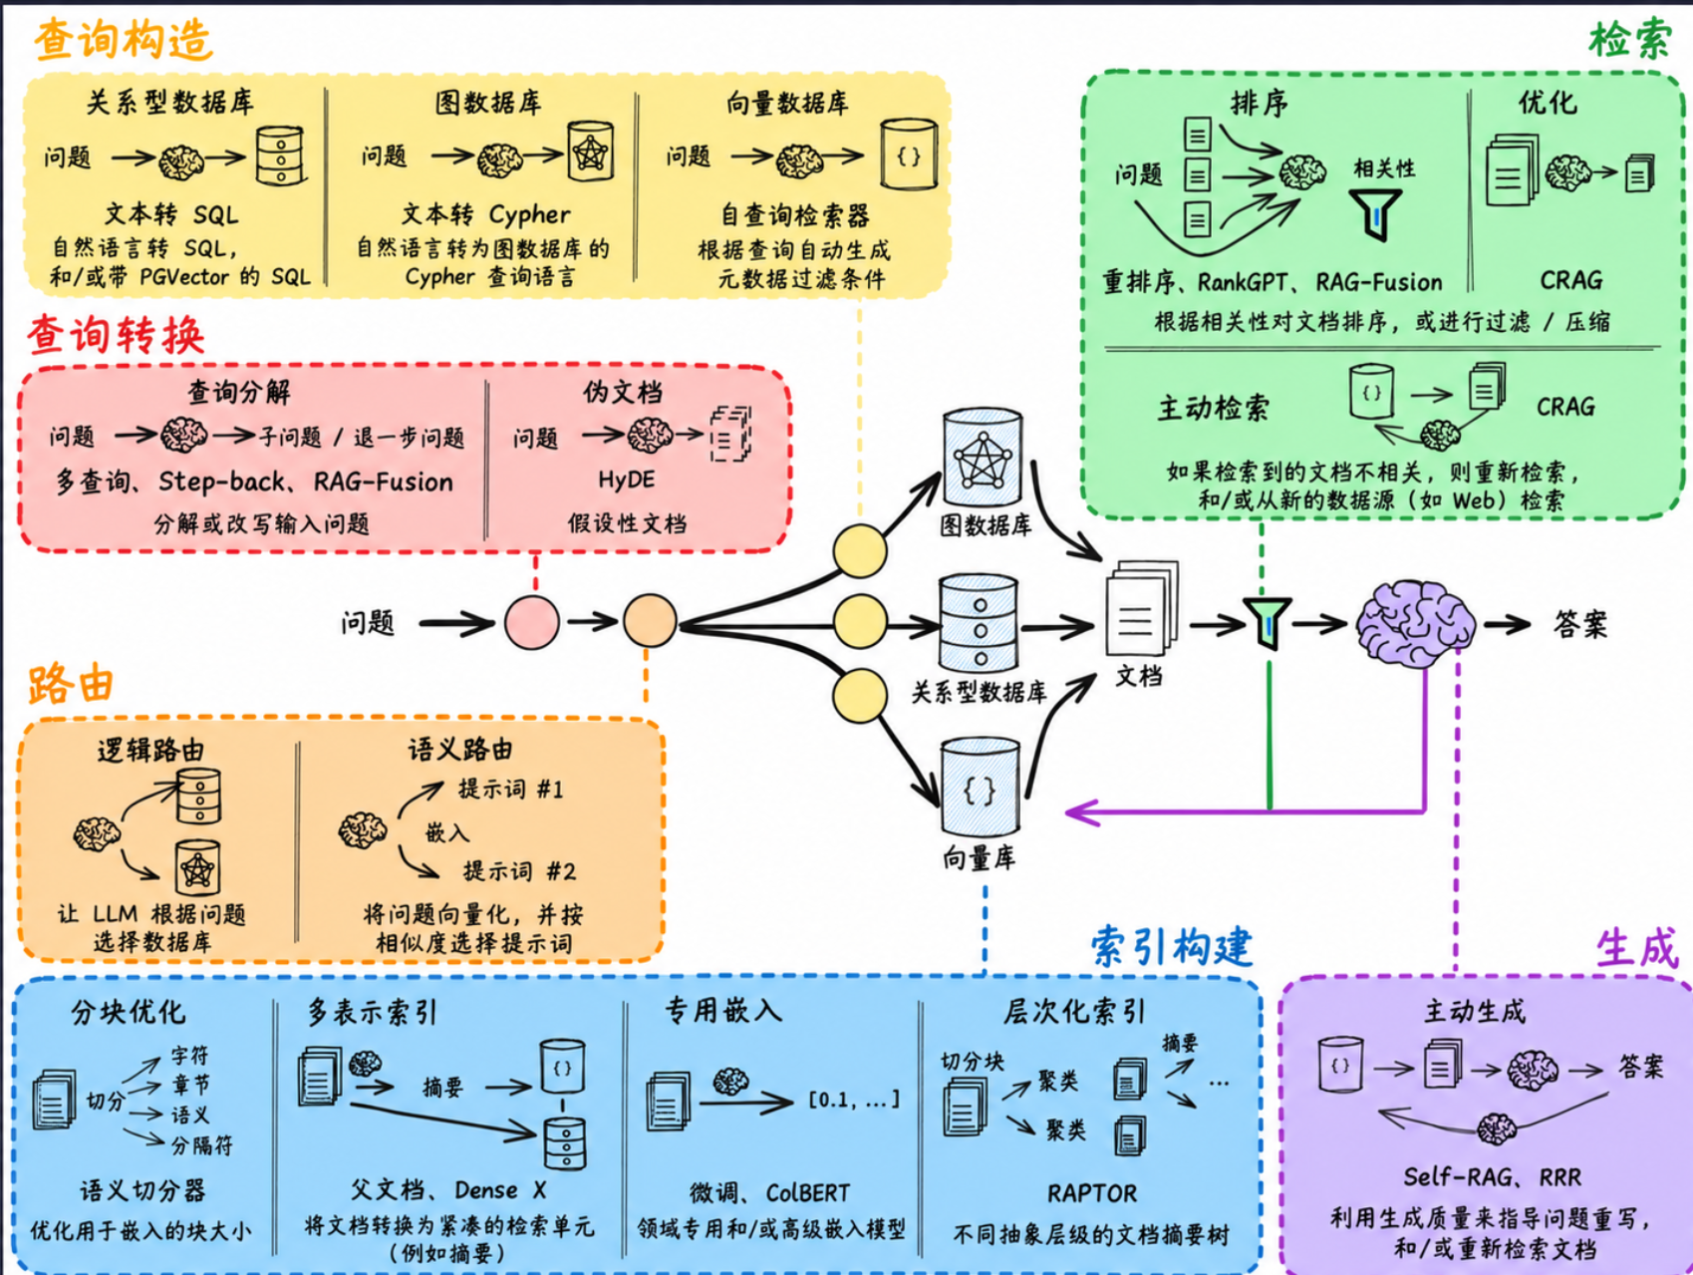

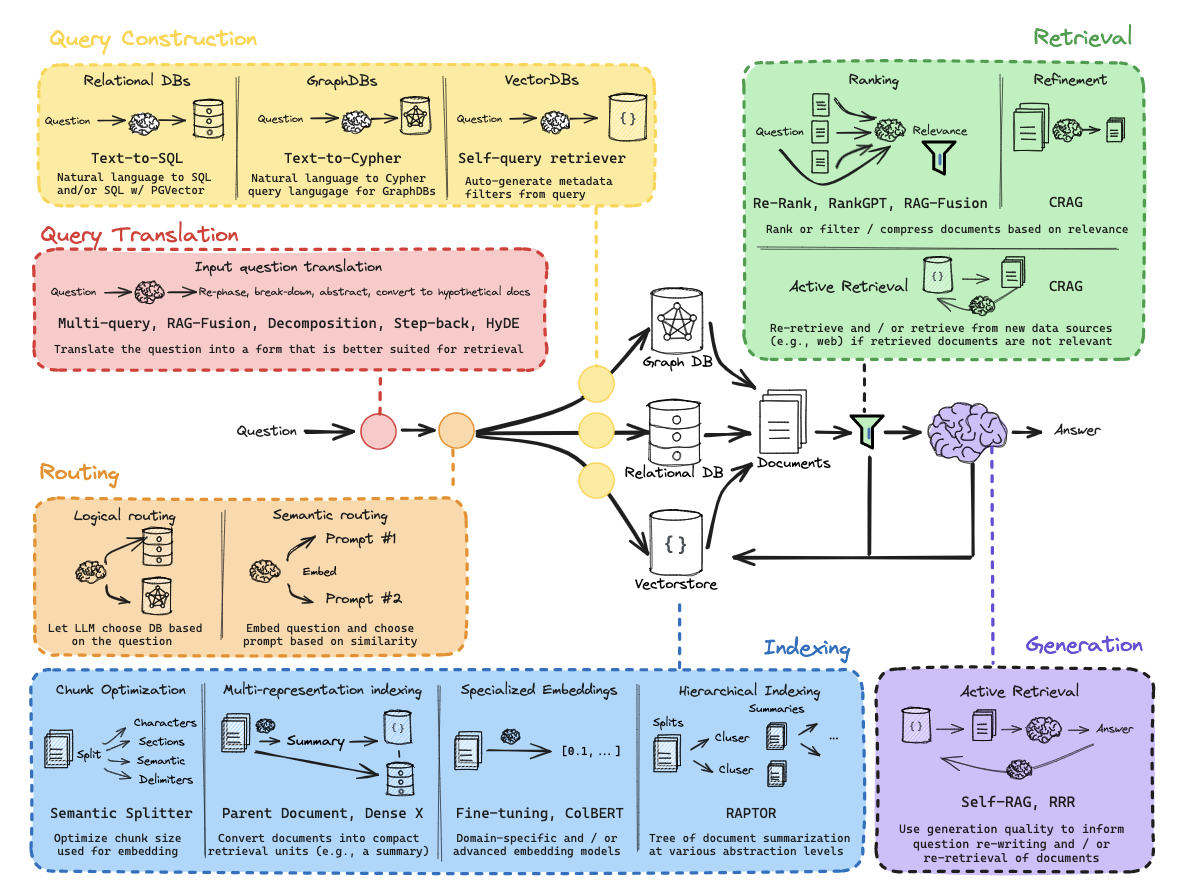

## Environment



In [3]:
from rag_config import load_config, show_config
load_config()
show_config()  # Only show model names and whether a key is configured.


PARATERA_BASE_URL: https://llmapi.paratera.com/v1
PARATERA_CHAT_MODEL: Qwen3.8-Flash
PARATERA_EMBEDDING_MODEL: GLM-Embedding-3
PARATERA_API_KEY configured: True


## Part 1: Overview
 
[RAG quickstart](https://python.langchain.com/docs/use_cases/question_answering/quickstart)

In [ ]:
import bs4
from rag_config import rag_prompt

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_chroma import Chroma
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from rag_config import make_chat_model, make_embeddings

#### INDEXING ####

# Load Documents
loader = WebBaseLoader(
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",),
    bs_kwargs=dict(
        parse_only=bs4.SoupStrainer(
            class_=("post-content", "post-title", "post-header")
        )
    ),
)
docs = loader.load()

# Split
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
splits = text_splitter.split_documents(docs)

# Embed
vectorstore = Chroma.from_documents(documents=splits, 
                                    embedding=make_embeddings())

retriever = vectorstore.as_retriever()

#### RETRIEVAL and GENERATION ####

# Prompt
prompt = rag_prompt()

# LLM
llm = make_chat_model(temperature=0)

# Post-processing
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# Chain
rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

# Question
rag_chain.invoke("What is Task Decomposition?")

C:\Users\86157\AppData\Local\Temp\ipykernel_25212\761378150.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


'Task decomposition is the process of breaking down a complicated task into smaller, manageable steps to facilitate planning and execution. It can be achieved through simple prompting with an LLM, using task-specific instructions, or incorporating human inputs. This technique allows agents to handle complex problems by transforming them into multiple simpler subtasks.'

## Part 2: Indexing 

把question和document转化成方便检索的形式。


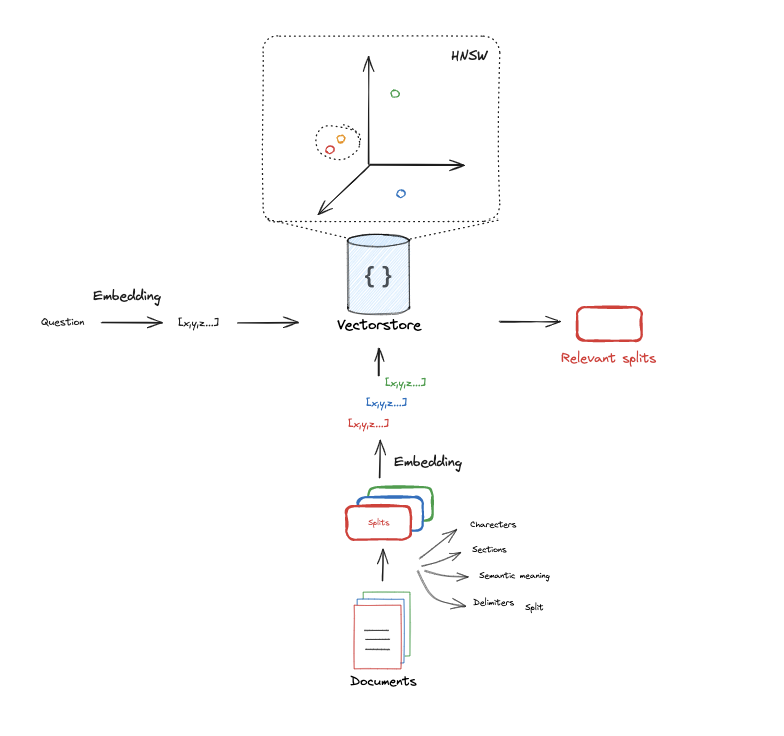

## splits (Chunking分块)

由于文档太大，内容太多，如果全部输入到llm里面，无关内容就比较多。所以对document文件切块（多种方法），把文件内容分为多个splits，每个chunk类似于一个小节，这样在检索式时可以更精细的检索。

- 切块的质量很重要，如果切不好，把一部分内容切到另一部分了，就可能缺少必要的上下文

## Embedding

把每个文字切块变成向量，比较语义相似度
## Vectorstore （向量存储）

用来存储和检索

- 常见的有Chroma向量库，一条记录保存如下信息：
    - id：一个chunk的标识
    - document：原始文档内容的chunk
    - embedding：文本对应的向量形式
    - metadata：文档的附加信息（来源，章节等）

## HNSW
一种常用于近似最近邻搜索的索引结构。

可以查找对于question向量点，附近最近的k(=1)个向量点，把这些相关的点检索出来

## Relevant Splits

如果有三个块，救会返回三个Relevant Splits，最后会合并成一个context上下文交给LLM



In [9]:
# Documents
question = "What kinds of pets do I like?"
document = "My favorite pet is a cat."

[Count tokens](https://github.com/openai/openai-cookbook/blob/main/examples/How_to_count_tokens_with_tiktoken.ipynb) considering [~4 char / token](https://help.openai.com/en/articles/4936856-what-are-tokens-and-how-to-count-them)

- 计算一段文本经过指定 Tokenizer 编码后，包含多少个 Token。


因为 RAG 需要把检索到的多个文档放进 context，而大模型的输入长度有限，我们需要估算问题、文档和 Prompt 一共占用了多少 Token。


# tiktoken
- OpenAI的Tokenizer（分词编码器）库，把`文本`按照encoding_name的编码策略，转成`token序列`
- 如果没有这个的话，就会用字符数来计算长度len




In [6]:
import tiktoken

encoding_name="cl100k_base"
encoder=tiktoken.get_encoding(encoding_name)
tokens=encoder.encode("hello world! a")

print(tokens)
print(len(tokens))

[15339, 1917, 0, 264]
4


In [7]:
import tiktoken
# string：需要计算token的文本。encoding_name：编码器名称
def num_tokens_from_string(string: str, encoding_name: str) -> int: 
    # :str 和 -> int 叫作类型注解，不会强制
    """Returns the number of tokens in a text string."""
    
    encoding = tiktoken.get_encoding(encoding_name)
    num_tokens = len(encoding.encode(string))  #string在这种编码下，返回一个list[token1,token2...]有多长
    return num_tokens

num_tokens_from_string(question, "cl100k_base")

8

# 余弦相似度
[Cosine similarity](https://platform.openai.com/docs/guides/embeddings/frequently-asked-questions) is recommended (1 indicates identical) for OpenAI embeddings.

计算 用户问题的向量和文档向量之间的余弦相似度（Cosine Similarity）。

- np.dot(vec1, vec2)
- np.linalg.norm(vec1)  求L2范式

In [ ]:
# 嵌入，转变成向量
from rag_config import make_embeddings
embd = make_embeddings()  
query_result = embd.embed_query(question)  # 把数值转化成向量
document_result = embd.embed_query(document)

In [10]:
import numpy as np
def cosine_similarity(vec1, vec2):
    dot_product = np.dot(vec1, vec2)
    norm_vec1 = np.linalg.norm(vec1)
    norm_vec2 = np.linalg.norm(vec2)
    return dot_product / (norm_vec1 * norm_vec2)

similarity = cosine_similarity(query_result, document_result)
print("Cosine Similarity:", similarity)

Cosine Similarity: 0.6409463276423477


# 1. load()加载数据

blog_docs = loader.load()

[Document Loaders](https://python.langchain.com/docs/integrations/document_loaders/)


In [3]:
#### INDEXING ####

# Load blog
import bs4  #BeautifulSoup库，处理html/xml，提取里面的特定信息
from langchain_community.document_loaders import WebBaseLoader #把指定网页的信息加载到文档,将解析结果转换成 LangChain 的 Document 对象。

#解析网页信息
loader = WebBaseLoader(
    # 存放的是元组，可以放多个页面链接
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",), 
    bs_kwargs=dict(
        # parse_only，只解析符合下面条件的
        parse_only=bs4.SoupStrainer(
            #只提取html的class属性是这三个的内容
            class_=("post-content", "post-title", "post-header") #class_ 末尾的下划线，为了区分python的类
        )
    ),
)

# ***加载document信息***
blog_docs = loader.load()

print(blog_docs) 
print(type(blog_docs[0]))  
#document对象：
#包含 page_content：文本内容。metadata：来源网址等附加信息。


C:\Users\86157\AppData\Local\Temp\ipykernel_9488\2173725419.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader #把指定网页的信息加载到文档,将解析结果转换成 LangChain 的 Document 对象。
USER_AGENT environment variable not set, consider setting it to identify your requests.


[Document(metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='\n\n      LLM Powered Autonomous Agents\n    \nDate: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng\n\n\nBuilding agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview#\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistake

# Split切块

[Splitter](https://python.langchain.com/docs/modules/data_connection/document_transformers/recursive_text_splitter)

这种文本分割器是针对通用文本推荐使用的分割器。它通过一个字符列表进行配置，并按照列表中的顺序依次尝试使用这些字符进行分割，直到每个文本块都足够小。

默认的分隔符列表是： ["\n\n", "\n", " ", ""]

这种设计的效果是：尽可能完整地保留段落，其次是句子，最后是单词。因为一般来说，这些文本单元内部的语义关联性更强，所以应尽可能避免将它们拆开。

1. **"\n\n**"：两个换行符，通常表示段落之间的空行。优先按段落切分。
2. **"\n"**：单个换行符。如果按段落切分后，文本块仍然太大，就尝试按换行切分。
3. **" "**：空格。如果文本块还是太大，就尝试按空格切分。
4. **""**：最后的兜底方式，在字符之间进行切分。

```bash
splits
│
├── Document 
│   │—— id： 0
│   ├── page_content：第一个文本块
│   └── metadata：来源网页等信息
│
├── Document 
│   │—— id： 1
│   ├── page_content：第二个文本块
│   └── metadata：来源网页等信息
│
└── ...
```

In [4]:
# Split
from langchain_text_splitters import RecursiveCharacterTextSplitter

#创建文本分割器
# tiktoken： 如果不加，直接RecursiveCharacterTextSplitter( )就会按照字符算这个300
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=300, # 每个块的大小：300 token
    chunk_overlap=50)  
#相邻文本之间叠加50 token。比如第一个1-300，第二个251-550（300个），第三个501-80（300个）
#减少切分边界处的信息丢失，避免上一块末尾的内容与下一块开头完全断开。

# Make splits
splits = text_splitter.split_documents(blog_docs)

print(splits[0])  # 第一个文本块，一个 LangChain的 Document 对象


page_content='LLM Powered Autonomous Agents
    
Date: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng


Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.
Agent System Overview#
In a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:

Planning

Subgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.
Reflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, thereby improving the quality of final results.


Memory' metadata={'sour

# 2.Embedding
[Text embedding models](https://python.langchain.com/docs/integrations/text_embedding/openai)


In [6]:
# Documents
question = "What kinds of pets do I like?"
document = "My favorite pet is a cat."

In [7]:
from rag_config import make_embeddings

embd = make_embeddings()  #用什么大模型创建embedding组件，内容封装在了rag_config这个文件里了。

query_result = embd.embed_query(question)  # 把数值转化成向量
document_result = embd.embed_query(document)

print(query_result[:5])
len(query_result)

[-0.004870871, -4.7680296e-05, -0.0042787064, 0.047857, -0.013899496]


2048

# 4. 送入向量数据库

把分块经过embedding之后，送入向量库
[Vectorstores](https://python.langchain.com/docs/integrations/vectorstores/)

In [11]:
# Index
from rag_config import make_embeddings
from langchain_chroma import Chroma

vectorstore = Chroma.from_documents(documents=splits, #split得到的所有文本块
                                    embedding=make_embeddings()) # 会把所有的split块全部执行一遍embedding，然后存入Chroma库里面


## Part 3: Retrieval  检索
### .as_retriever(...)
- search_type="similarity"

用相似度策略，进行检索排序（下面都用相似度策略举例）
- search_kwargs={"k": 3}

返回最多3个相似度最接近的向量
- score_threshold=0.7

相似度分数阈值，低于阈值的结果可被过滤

In [13]:
#创建检索器

#把 Chroma向量存储库转换成一个检索器，给它一个问题，它就能帮你找出相关的文档切块。
#
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

In [6]:
#检索器的 invoke 方法

#把 question 交给检索器，让它返回相关的文档块向量
question="What is Task Decomposition?"

docs = retriever.invoke(question)

In [7]:
print(docs)
len(docs)

[Document(id='650e91b1-a01e-42a8-b53f-e6c901a8a16e', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple manageable tasks and shed lights into an interpretation of the model’s thinking process.\nTree of Thoughts (Yao et al. 2023) extends CoT by exploring multiple reasoning possibilities at each step. It first decomposes the problem into multiple thought steps and generates multiple thoughts per step, creating a tree structure. The search process can be BFS (breadth-first search) or DFS (depth-f

2

## Part 4: Generation

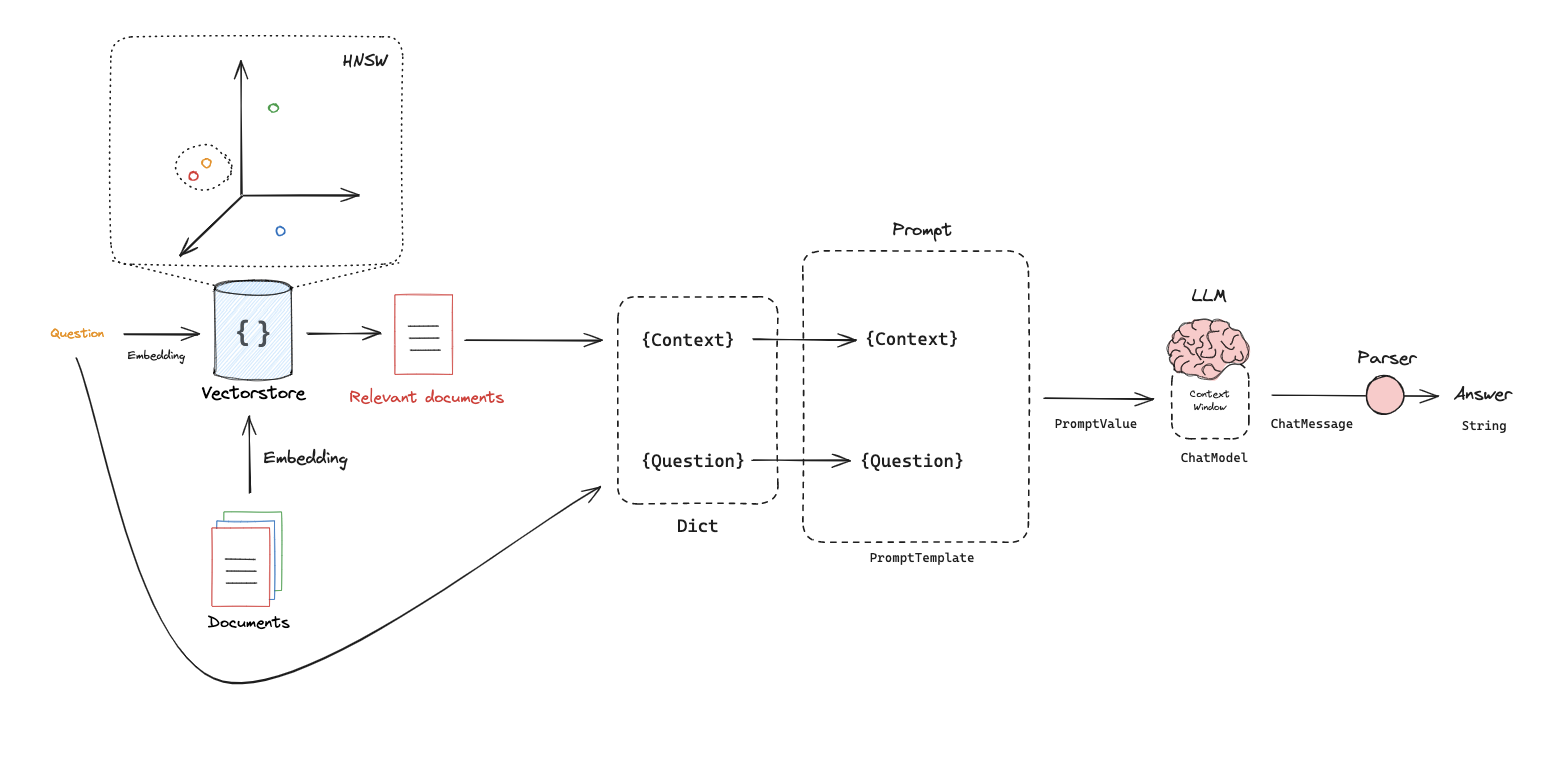

- 检索出来的document向量拼成一个大的上下文context，结合上question形成一个字典。
- 字典填充到提示词里面
- 提示词传给LLM，生成答案

In [15]:
from rag_config import make_chat_model
#导入 LangChain 的聊天提示词模板
from langchain_core.prompts import ChatPromptTemplate

# Prompt 提示词模版
template = """基于下面的上下文做出回答:
{context}

问题stion: {question}
"""
# 将普通字符串转换成 LangChain 的聊天提示词模板对象,ChatPromptTemplate对象
prompt = ChatPromptTemplate.from_template(template)
prompt

ChatPromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, messages=[HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template='基于下面的上下文做出回答:\n{context}\n\n问题stion: {question}\n'), additional_kwargs={})])

In [17]:
# LLM
# 创建一个llm模型
#当 temperature 较高时，模型的采样通常会更分散，低概率候选词也可能被选中；
#当 temperature 降低时，概率分布通常会更加集中，模型更倾向于选择高概率的候选词。
llm = make_chat_model(temperature=0)

In [18]:
# Chain
# LangChain 提供的链式组合操作符。
chain = prompt | llm

## 生成器表达式
```bash
context="\n\n".join(
    docu.page_content  for docu in docs
)
```

列表推导式一次性把所有结果存入内存，生成器表达式惰性求值，用一个算一个，不一次性存全部。

- 先遍历for docu in docs，得到docu
- 输出docu.page_content
- 如果是列表表达式，就是直接把所有的返回值一次性执行一次join


| 对比项 | 列表推导式 `[expr for ...]` | 生成器表达式 `(expr for ...)` |
| --- | --- | --- |
| 符号 | 方括号 `[]` | 圆括号 `()`，传给 `join/map` 时括号可以省略 |
| 内存 | 立刻生成完整列表，所有元素都放内存 | 没有把结果存入输出，若有迭代的时候才逐个算出 |
| 求值方式 | 急切求值（eager） | 惰性求值（lazy） |
| 可重复遍历 | ✅ 可以多次遍历，数据一直在 | ❗ 遍历一次之后就耗尽了，第二次遍历是空 |
| 速度（少量数据） | 略快一点 | 略慢，因为每次迭代要触发计算 |
| 适合场景 | 数据量小、需要多次读取、需要索引取值（`lst[0]`） | 数据量大、只遍历一次（传给 join/for 循环），省 |




In [ ]:
# 列表推导式：全部生成在内存里
lst = [i*i for i in range(10)]

# 生成器表达式：只是一个规则，没有存全部结果
gen = (i*i for i in range(10))

print(lst)
print(gen)  # 打印不出来，生成器本身不是一堆数据，它是一个 “待执行的计算规则 / 流水线”**。

gen = (i for i in "abcd")
text1 = " ".join(gen)   #这里不是打印，而是用东西接住他，迭代他，把里面的东西取出来。比比如说list(gen)
text2 = " ".join(gen)   # text2 是空字符串！生成器已经耗尽

print("text1:",text1)
print("text2:",text2)


gen = (i for i in "abcd")
lst=list(gen)
print("lst:",lst)


# 2.对比列表表达式的不同
context="*".join(
    str  for str in "abcd"   # 需要有操作，把()的流水线取出来执行以下才行
)
print(context)

context=[
    str  for str in "abcd"   # 直接放到列表，返回元素
]
print(context)



[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
<generator object <genexpr> at 0x0000022B9FF70860>
text1: a b c d
text2: 
lst: ['a', 'b', 'c', 'd']
a*b*c*d
['a', 'b', 'c', 'd']


In [ ]:
# Run

#有多个检索出来的doc时：
# 1. 需要拼接，用 "...".join()来拼接字符串
# 2. doc记录里有： id  metadata  page_content 我们只需要page_content正文，所以需要提取一下。让提示词上下文更干净

context="\n\n".join(   # 把docu的正文字段取出来，用两个回车拼成一个大的context
    docu.page_content  for docu in docs
)

# invoke：

# 对于不同的组件作用也不同，在这里就是接受一个输入返回一个输出，
# 把当前括号里的输入到chain的第一个组件（prompt），返回的是链中最后一个组件(llm)的输出。
# 把检索出来的多个context和question，组成字典，传入chain里，prompt接收字典。
res=chain.invoke({"context":context,
                "question":"What is Task Decomposition?"}) # 传给prompt

# 最后llm的输出回答
print(res)
print(type(res))

content='Based on the provided context, **Task Decomposition** is a process where an agent or model breaks down a complicated task into smaller, simpler, and more manageable steps to facilitate planning and execution.\n\nKey aspects of Task Decomposition include:\n\n1.  **Purpose**: It helps agents understand what steps are involved in a complex task and allows them to plan ahead.\n2.  **Techniques**:\n    *   **Chain of Thought (CoT)**: Instructs the model to "think step by step," utilizing more computation time to split hard tasks into simpler ones. This also provides insight into the model\'s reasoning process.\n    *   **Tree of Thoughts (ToT)**: Extends CoT by exploring multiple reasoning possibilities at each step, creating a tree structure that can be searched using BFS or DFS, with states evaluated by classifiers or majority votes.\n3.  **Methods of Execution**: Task decomposition can be achieved through:\n    *   Simple prompting (e.g., asking for "Steps for XYZ" or "subgoals"

## 以上
- 以上已经输出了llm的回答，prompt的内容没有打印，他直接通过|传递到了llm里面。
- 返回的res，就是最终llm的回答
- 想看中间过程以及prompt，请看[https://smith.langchain.com/o/44eaae46-524d-47a0-b9eb-014b26b51b6b/a/default/projects/p/574006e6-64d7-426e-93ef-db1d9e464cda?peek=01a17d95-cccd-7586-adf2-e79a2162dfb6&peeked_trace=01a17d95-ccca-73f2-b6d4-b68ee158a945&start_time=2026-10-27T13%3A38%3A51.724673Z&peek_project=574006e6-64d7-426e-93ef-db1d9e464cda&scroll_to=feedback]

In [ ]:
from rag_config import rag_prompt
# 如果不用自己定义的模版，也可以用rag_config定义的模版
#或者说，一般都是在rag_config里面定义模版，然后再调用它
prompt2 = rag_prompt()
print(prompt2)

#若希望链使用它：
# chain = prompt_hub_rag | llm

# response = chain.invoke({
#     "context": context,
#     "question": "What is Task Decomposition?"
# })


input_variables=['context', 'question'] input_types={} partial_variables={} messages=[HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template="You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. If you don't know the answer, just say that you don't know. Use three sentences maximum and keep the answer concise.\nQuestion: {question}\nContext: {context}\nAnswer:"), additional_kwargs={})]


[RAG chains](https://python.langchain.com/docs/expression_language/get_started#rag-search-example)

这段代码是你之前学习的 RAG 流程的自动化版本。之前你需要手动检索文档、提取 page_content、拼接 context，再调用 Prompt 和大模型；现在通过 LangChain 的链式组合，把这些步骤连接起来了。

最重要的是：你只需要输入一个问题，整条链就会自动完成检索、组织上下文、生成回答，并将结果转换成字符串。

- 首先传入question：What is Task Decomposition?
- 进入chain之后进入字典，一个question会输入到两个分支：
    - question--->`context`：检索，把检索后的docs加入上下文（这里直接把全部的docu字块放进来，没有进行处理，prompt只会对docs做基本的格式化）
    - question--->`question`：把问题原样放进来
- 字典填充好之后传给prompt填入信息
- 传给llm，得到AIMessage类型的输出
- 用StrOutputParser() 转化成字符串str形式

In [ ]:
#StrOutputParser() 将大模型返回的消息提取为普通字符串。
from langchain_core.output_parsers import StrOutputParser
# RunnablePassthrough() 把输入原样传递下去，不额外修改它。
from langchain_core.runnables import RunnablePassthrough  

rag_chain = (
    {"context": retriever, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser() 
)

rag_chain.invoke("What is Task Decomposition?")

'Based on the provided context, **Task Decomposition** is a planning component for agents that involves breaking down complicated tasks into smaller, simpler, and more manageable steps.\n\nKey aspects of Task Decomposition include:\n\n*   **Purpose:** It allows an agent to understand what steps are involved in a complex task and plan ahead by utilizing more test-time computation.\n*   **Techniques:**\n    *   **Chain of Thought (CoT):** A standard prompting technique where the model is instructed to "think step by step," transforming big tasks into multiple manageable ones.\n    *   **Tree of Thoughts (ToT):** An extension of CoT that explores multiple reasoning possibilities at each step, creating a tree structure searched via BFS or DFS.\n*   **Methods of Execution:** Task decomposition can be achieved through:\n    1.  Using Large Language Models (LLMs) with simple prompting (e.g., asking for "Steps for XYZ" or "subgoals").\n    2.  Using task-specific instructions (e.g., "Write a s